# 02 &nbsp;Does a fine-tuned small model beat a prompted large one on the same messages?

**The problem.** A team choosing between fine-tuning a small model and prompting a large hosted one needs to know which gets more answers right on their messages, and by how much. Comparing two headline accuracies measured on different messages mixes up the approaches with the luck of which messages were tested.

**The approach.**

1. Score every option on exactly the same test messages.
2. Compare them in pairs, message by message, with 95% intervals from resampling those messages.
3. Ask a narrower question too: given the *same* 385 labelled examples, is it better to put them in a prompt or to train on them?
4. Read the messages that every option gets wrong, to see how much of the remaining error is the models and how much is the labels.

**The options.**

| Option | What it is | Labelled examples used |
|---|---|---|
| Small model, not fine-tuned | bge-small embeddings (33M parameters) plus logistic regression | all 9,000 |
| Small model, fine-tuned | ModernBERT-base (150M parameters), fine-tuned on a laptop GPU, three runs | all 9,000 |
| Claude Haiku 5.5, prompted | The 77 intent names, with 0, 1 or 5 examples of each in the prompt | 0, 77 or 385 |
| Claude Sonnet 5.5, prompted | The same prompts | 0, 77 or 385 |

To keep the API bill down, Sonnet answered 20 messages of each intent (1,540) instead of all 3,080. Every comparison in this notebook uses those 1,540 messages, so all options face the same questions. Each prompted model was run once; the fine-tuned model's score is the average of its three training runs. Section 7 adds two runs that give the prompted models all 9,000 labels, by retrieving the most similar labelled examples for each message.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fopstudy import plots, style
from fopstudy.data import load_labels, load_split
from fopstudy.evaluate import bootstrap_mean, paired_difference
from fopstudy.results import RESULTS_DIR, correctness, load_predictions

style.use_style()
test = load_split("test")
labels = load_labels()

# Each option's correctness on every message: 0 or 1, or the share of three runs that got it right.
options = {
    "Small model, not fine-tuned": ("frozen", correctness("frozen", "all")),
    "Small model, fine-tuned": ("finetuned", correctness("finetuned", "all", seeds=(0, 1, 2))),
}
for model in ["sonnet", "haiku"]:
    for shots in [5, 1, 0]:
        name = f"{style.APPROACH_LABELS[model].split(',')[0]}, {shots} example{'s' if shots != 1 else ''} per intent"
        options[name] = (model, correctness(model, shots))

rows = options[next(k for k in options if k.startswith("Claude Sonnet"))][1].index  # the 1,540 Sonnet answered
same = pd.DataFrame({name: c.loc[rows] for name, (_, c) in options.items()})
print(f"{len(rows):,} messages, {test.loc[rows, 'label'].value_counts().iloc[0]} of each of the {test.loc[rows, 'label'].nunique()} intents")

1,540 messages, 20 of each of the 77 intents


## 1. Accuracy on the same 1,540 messages

In [2]:
acc = pd.DataFrame([bootstrap_mean(same[name]) for name in same], index=same.columns,
                   columns=["Accuracy", "95% low", "95% high"])
acc.index.name = "Option"
acc.style.format("{:.1%}")

,Accuracy,95% low,95% high
Option,,,
"Small model, not fine-tuned",92.2%,90.8%,93.5%
"Small model, fine-tuned",93.3%,92.2%,94.4%
"Claude Sonnet 5.5, 5 examples per intent",89.9%,88.4%,91.4%
"Claude Sonnet 5.5, 1 example per intent",87.3%,85.6%,89.0%
"Claude Sonnet 5.5, 0 examples per intent",84.0%,82.2%,85.8%
"Claude Haiku 5.5, 5 examples per intent",86.7%,85.0%,88.4%
"Claude Haiku 5.5, 1 example per intent",82.5%,80.6%,84.3%
"Claude Haiku 5.5, 0 examples per intent",79.0%,77.0%,81.0%


## 2. The fine-tuned model against each other option, message by message

Each difference below is the fine-tuned model's accuracy minus the other option's, measured on the same messages. Pairing removes the noise of which messages happen to be easy, so the intervals are much tighter than the overlap of the two separate intervals above would suggest.

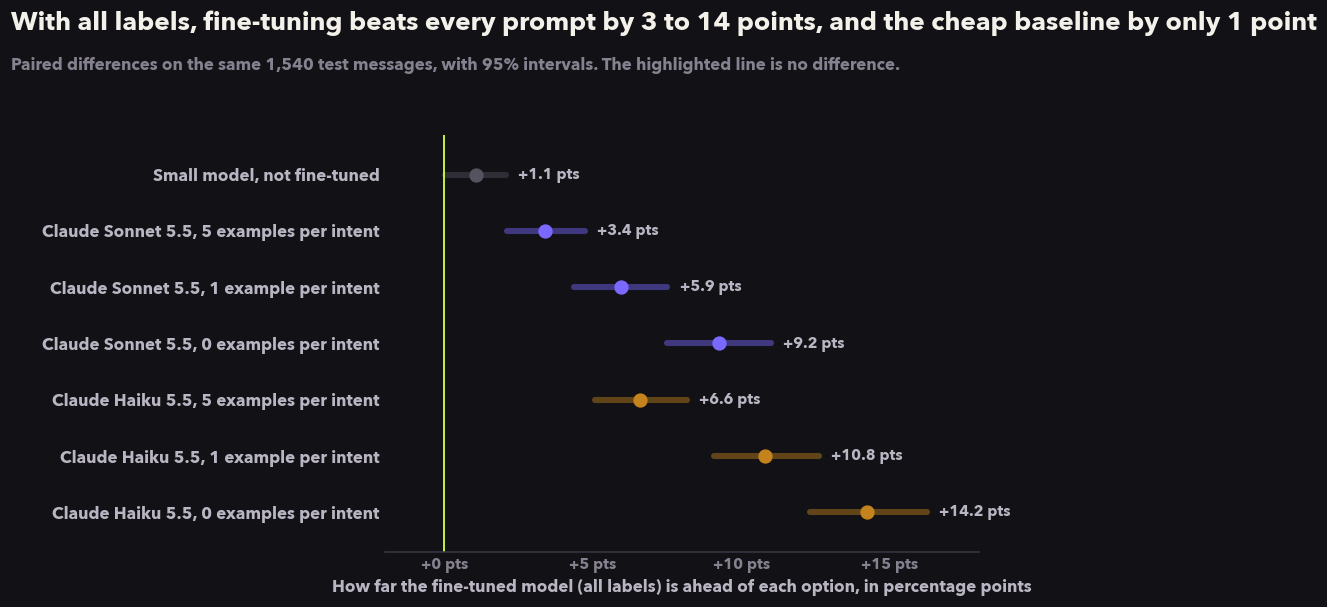

In [3]:
ft = same["Small model, fine-tuned"]
others = [name for name in same if name != "Small model, fine-tuned"]
diff = pd.DataFrame([paired_difference(ft, same[name]) for name in others], index=others,
                    columns=["value", "low", "high"]).reset_index(names="label")
diff["colour"] = [style.APPROACH_COLORS[options[name][0]] for name in diff["label"]]
fig, ax = plots.dot_intervals(diff, value_format=lambda v: f"{v * 100:+.1f} pts")
ax.set_xticks([0, 0.05, 0.10, 0.15])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v * 100:+.0f} pts"))
ax.set_xlabel("How far the fine-tuned model (all labels) is ahead of each option, in percentage points")
ax.set_xlim(-0.02, 0.18)
fig.subplots_adjust(top=0.78, left=0.36)
prompted = diff[~diff["label"].str.contains("not fine-tuned")]
style.headline(fig,
               f"With all labels, fine-tuning beats every prompt by {prompted['value'].min() * 100:.0f} to "
               f"{prompted['value'].max() * 100:.0f} points, and the cheap baseline by only "
               f"{diff['value'].iloc[0] * 100:.0f} point",
               "Paired differences on the same 1,540 test messages, with 95% intervals. "
               "The highlighted line is no difference.")
style.save(fig, "finetuned_vs_each_option")

In [4]:
full = paired_difference(correctness("finetuned", "all", seeds=(0, 1, 2)), correctness("frozen", "all"))
print(f"Fine-tuned minus not fine-tuned on all 3,080 test messages: {full[0] * 100:+.1f} points "
      f"(95% interval {full[1] * 100:+.2f} to {full[2] * 100:+.2f})")

Fine-tuned minus not fine-tuned on all 3,080 test messages: +0.7 points (95% interval -0.02 to +1.37)


Against the model that was not fine-tuned, the gap is about one point. On these 1,540 messages its interval only just clears zero, and on the full 3,080 messages it does not, so the two are close to a tie. Among the prompts, more examples and the larger model both help, but even Sonnet with five examples of every intent stays a few points behind.

## 3. The same 385 labelled examples, used three ways

Suppose a team has labelled only 5 messages per intent (385 in all). They can put those examples in the prompt of a hosted model, or train a small model on them. The prompted runs above used exactly the 385 examples that the small models were trained on in their first run, so this is a like-for-like test of what to do with a small labelled set.

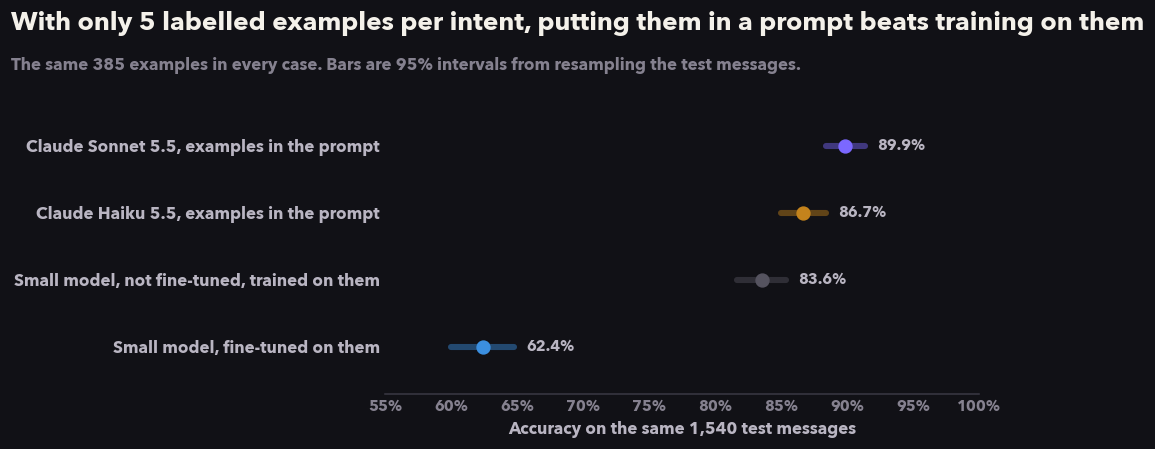

In [5]:
few = pd.DataFrame({
    "Claude Sonnet 5.5, examples in the prompt": correctness("sonnet", 5).loc[rows],
    "Claude Haiku 5.5, examples in the prompt": correctness("haiku", 5).loc[rows],
    "Small model, not fine-tuned, trained on them": correctness("frozen", 5).loc[rows],
    "Small model, fine-tuned on them": correctness("finetuned", 5).loc[rows],
})
few_rows = pd.DataFrame([bootstrap_mean(few[name]) for name in few], columns=["value", "low", "high"])
few_rows["label"] = few.columns
few_rows["colour"] = [style.APPROACH_COLORS[a] for a in ["sonnet", "haiku", "frozen", "finetuned"]]

fig, ax = plots.dot_intervals(few_rows, value_format="{:.1%}", zero_line=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Accuracy on the same 1,540 test messages")
ax.set_xlim(0.55, 1.0)
fig.subplots_adjust(top=0.78, left=0.36)
style.headline(fig, "With only 5 labelled examples per intent, putting them in a prompt beats training on them",
               "The same 385 examples in every case. Bars are 95% intervals from resampling the test messages.")
style.save(fig, "same_385_examples")

In [6]:
gaps = {
    "Haiku prompt minus small model, not fine-tuned": paired_difference(few.iloc[:, 1], few.iloc[:, 2]),
    "Haiku prompt minus small model, fine-tuned": paired_difference(few.iloc[:, 1], few.iloc[:, 3]),
    "Sonnet prompt minus Haiku prompt": paired_difference(few.iloc[:, 0], few.iloc[:, 1]),
}
pd.DataFrame(gaps, index=["Difference", "95% low", "95% high"]).T.style.format(lambda v: f"{v * 100:+.1f} pts")

,Difference,95% low,95% high
"Haiku prompt minus small model, not fine-tuned",+3.1 pts,+1.3 pts,+4.9 pts
"Haiku prompt minus small model, fine-tuned",+24.3 pts,+21.8 pts,+26.8 pts
Sonnet prompt minus Haiku prompt,+3.2 pts,+1.9 pts,+4.4 pts


Fine-tuning a 150M-parameter model on 5 examples per intent works badly: it gets about two in three right, and the three training runs disagree by several points (notebook 03 shows the spread). The same model needs many more labels before training pays off.

## 4. Do the options fail on the same messages?

If the fine-tuned model and a prompted model made different mistakes, a team could combine them, for example by sending the messages they disagree on to a person. The table compares the fine-tuned model (first run) with Haiku given five examples, on the full test set.

In [7]:
a = load_predictions("finetuned", "all", 0).set_index("row")["correct"]
b = load_predictions("haiku", 5, 0).set_index("row")["correct"]
pd.crosstab(a.rename("Fine-tuned (all labels)").map({True: "right", False: "wrong"}),
            b.rename("Haiku, 5 examples").map({True: "right", False: "wrong"}), margins=True, margins_name="Total")

"Haiku, 5 examples",right,wrong,Total
Fine-tuned (all labels),,,
right,2600,268,2868
wrong,87,125,212
Total,2687,393,3080


When Haiku is wrong, the fine-tuned model is usually right. When the fine-tuned model is wrong, Haiku is wrong too more often than not. So the fine-tuned model's mistakes are mostly a subset of hard messages that Haiku also misses, and combining the two would gain little.

In [8]:
any_right = (same > 0).any(axis=1)
none_right = ~any_right
print(f"On the 1,540 messages, at least one of the eight options gets {any_right.mean():.1%} right; "
      f"{none_right.sum()} messages are missed by every option.")

On the 1,540 messages, at least one of the eight options gets 97.8% right; 34 messages are missed by every option.


## 5. Reading the messages that every option gets wrong

Notebook 01 found that the most common errors are between look-alike intents and asked whether some are labelling problems rather than model mistakes. Here, the messages missed by all four main options (the two small models trained on all labels, and Haiku and Sonnet with five examples) were read one by one and given one of three verdicts:

- **Label looks wrong**: another intent fits the message clearly better than its label (most often the one the models chose).
- **Ambiguous**: the message is too short or vague to pick one intent; the label and the models' answer are both defensible.
- **Models wrong**: the label is right and the models missed it.

The verdicts are in [results/hand_check.csv](../results/hand_check.csv).

In [9]:
main = ["Small model, not fine-tuned", "Small model, fine-tuned",
        "Claude Sonnet 5.5, 5 examples per intent", "Claude Haiku 5.5, 5 examples per intent"]
all_miss = same.index[(same[main] == 0).all(axis=1)]
check = pd.read_csv(RESULTS_DIR / "hand_check.csv").set_index("row")
assert set(check.index) == set(all_miss), "hand check must cover exactly the messages every option misses"

verdicts = check["verdict"].value_counts()
pd.DataFrame({"Messages": verdicts, "Share of the 1,540": verdicts / len(rows)}).rename_axis("Verdict").style.format(
    {"Share of the 1,540": "{:.1%}"})

,Messages,"Share of the 1,540"
Verdict,,
label looks wrong,23,1.5%
ambiguous,15,1.0%
models wrong,1,0.1%


In [10]:
shown = check[check["verdict"] != "ambiguous"].head(6).index.tolist() + \
        check[check["verdict"] == "ambiguous"].head(3).index.tolist()
sonnet5 = load_predictions("sonnet", 5, 0).set_index("row")
pd.DataFrame({
    "Message": test.loc[shown, "text"].to_numpy(),
    "Label": [labels[i].replace("_", " ") for i in test.loc[shown, "label"]],
    "Sonnet's answer": [labels[i].replace("_", " ") for i in sonnet5.loc[shown, "pred"]],
    "Verdict": check.loc[shown, "verdict"].to_numpy(),
}).style.hide(axis="index")

Message,Label,Sonnet's answer,Verdict
How long does a card delivery take?,card arrival,card delivery estimate,label looks wrong
"There is an incoming payment into my account, but it is deactivated. Will they still be processed?",fiat currency support,receiving money,label looks wrong
Am I able to exchange currencies?,fiat currency support,exchange via app,label looks wrong
my card was not in the mail again can you advise?,card delivery estimate,card arrival,label looks wrong
Will declined funds I tried to withdraw be returned to me?,wrong amount of cash received,declined cash withdrawal,label looks wrong
When will my funds transfer?,transfer not received by recipient,transfer timing,label looks wrong
When will I get my card?,card arrival,card delivery estimate,ambiguous
Why am I being charged more ?,card payment wrong exchange rate,extra charge on statement,ambiguous
My account was charged for a withdraw I tried to make that was decline.,pending cash withdrawal,declined cash withdrawal,ambiguous


In [11]:
wrong_label = (check["verdict"] == "label looks wrong").sum()
unclear = (check["verdict"] == "ambiguous").sum()
best = acc["Accuracy"].max()
print(f"{wrong_label} of the 1,540 labels ({wrong_label / len(rows):.1%}) look wrong and {unclear} more "
      f"({unclear / len(rows):.1%}) are ambiguous. If those count as unanswerable, the best option's "
      f"{best:.1%} sits about {(1 - best) * 100 - (wrong_label + unclear) / len(rows) * 100:.1f} points "
      f"below what is reachable, not {(1 - best) * 100:.1f}.")

23 of the 1,540 labels (1.5%) look wrong and 15 more (1.0%) are ambiguous. If those count as unanswerable, the best option's 93.3% sits about 4.3 points below what is reachable, not 6.7.


Most of what every option gets wrong is not a model failure. A few percent of Banking77's test labels are wrong or arguable, so no approach can reach 100%, and differences of a point or two near the top deserve less weight than they seem to. This check covers only the messages all four options miss; labels that are wrong where some option agrees with them are not counted, so the true share of bad labels is somewhat higher.

## 6. More right, or more in line with Banking77's labellers?

A model trained on 9,000 Banking77 labels learns how *these* labellers chose between look-alike intents: for example, that a question about fees at a foreign ATM is filed under the wrong exchange rate for cash withdrawals. A prompted model sees only the intent names and a few examples, so it cannot learn those habits. Part of the fine-tuned model's lead could therefore be agreement with the labellers rather than better answers.

To test this, every message on which exactly one of the two disagrees with the label was read: the fine-tuned model (first run) against Sonnet with five examples per intent. For the answer that does not match the label, the verdict is one of:

- **Label only**: the label is right and the other answer is a mistake.
- **Both defensible**: the message supports either intent.
- **Other answer better**: the other answer fits the message better than its label.

The verdicts are in [results/hand_check_disagreements.csv](../results/hand_check_disagreements.csv). They are one reader's judgement, and the reader was a Claude model, the same family as one of the two being judged, so they deserve a second reader's check.

In [12]:
dis = pd.read_csv(RESULTS_DIR / "hand_check_disagreements.csv").set_index("row")
ft1 = load_predictions("finetuned", "all", 0).set_index("row").loc[rows, "correct"]
s5 = load_predictions("sonnet", 5, 0).set_index("row").loc[rows, "correct"]
assert set(dis.index) == set(rows[ft1 != s5]), "verdicts must cover exactly the messages where the two disagree"
pd.crosstab(dis["matches_label"].map({"finetuned": "Fine-tuned matches the label", "sonnet": "Sonnet matches the label"}),
            dis["verdict"], margins=True, margins_name="Total").rename_axis(index=None, columns="Verdict on the other answer")

Verdict on the other answer,both defensible,label only,other answer better,Total
Fine-tuned matches the label,56,6,26,88
Sonnet matches the label,22,20,0,42
Total,78,26,26,130


In [13]:
# Lenient scoring: an answer also counts as right when it was judged at least as good as the label.
acceptable = dis["verdict"] != "label only"
lenient = {}
for name, strict in [("finetuned", ft1), ("sonnet", s5)]:
    lenient[name] = strict.astype(float).copy()
    other = dis.index[dis["other_answer"] == name]
    lenient[name].loc[other] = acceptable.loc[other].astype(float)
scores = pd.DataFrame({
    "Strict (must match the label)": paired_difference(ft1.astype(float), s5.astype(float)),
    "Lenient (defensible answers count)": paired_difference(lenient["finetuned"], lenient["sonnet"]),
}, index=["Fine-tuned minus Sonnet", "95% low", "95% high"]).T
scores["Fine-tuned accuracy"] = [ft1.mean(), lenient["finetuned"].mean()]
scores["Sonnet accuracy"] = [s5.mean(), lenient["sonnet"].mean()]
scores.style.format({c: (lambda v: f"{v * 100:+.1f} pts") for c in scores.columns[:3]} |
                    {c: "{:.1%}" for c in scores.columns[3:]})

,Fine-tuned minus Sonnet,95% low,95% high,Fine-tuned accuracy,Sonnet accuracy
Strict (must match the label),+3.0 pts,+1.6 pts,+4.4 pts,92.9%,89.9%
Lenient (defensible answers count),-0.9 pts,-1.6 pts,-0.3 pts,94.3%,95.2%


The two directions look very different. When the fine-tuned model matches the label and Sonnet does not, Sonnet's answer was usually defensible, and often fit the message better than the label. When Sonnet matches the label and the fine-tuned model does not, the fine-tuned model's answer was a plain mistake about half the time. Counting defensible answers as right, the fine-tuned model's three-point lead over Sonnet disappears, and Sonnet is slightly ahead.

So the fine-tuned model's advantage is mostly that it agrees with Banking77's labelling habits. That is worth something if a team's own labels define what a right answer is (for example, because each intent routes to a fixed queue). It is worth much less if any sensible reading of the message would do. This check covers only Sonnet with five examples; Haiku and the other prompts were not read this way.

## 7. Giving the prompt all the labels

Every comparison so far gave the prompted models at most 385 labelled examples, while the small models trained on 9,000. That is not a fair test of prompting with plenty of labels. A prompt cannot hold 9,000 examples, but it can hold the few that matter for each message: the labelled training messages most similar to it. Two more runs did exactly that. For every test message, the 10 most similar of the 9,000 training messages (by the frozen bge-small embeddings) went into the request with their labels, and the model chose the intent. Both models answered the same 1,540 messages.

,Difference,95% low,95% high
"Haiku, retrieved, minus fine-tuned",+1.0 pts,+0.2 pts,+1.9 pts
"Sonnet, retrieved, minus fine-tuned",+1.0 pts,+0.1 pts,+1.8 pts
"Haiku, retrieved, minus not fine-tuned",+2.1 pts,+0.9 pts,+3.2 pts
"Haiku, retrieved, minus Sonnet, retrieved",+0.1 pts,-0.6 pts,+0.7 pts


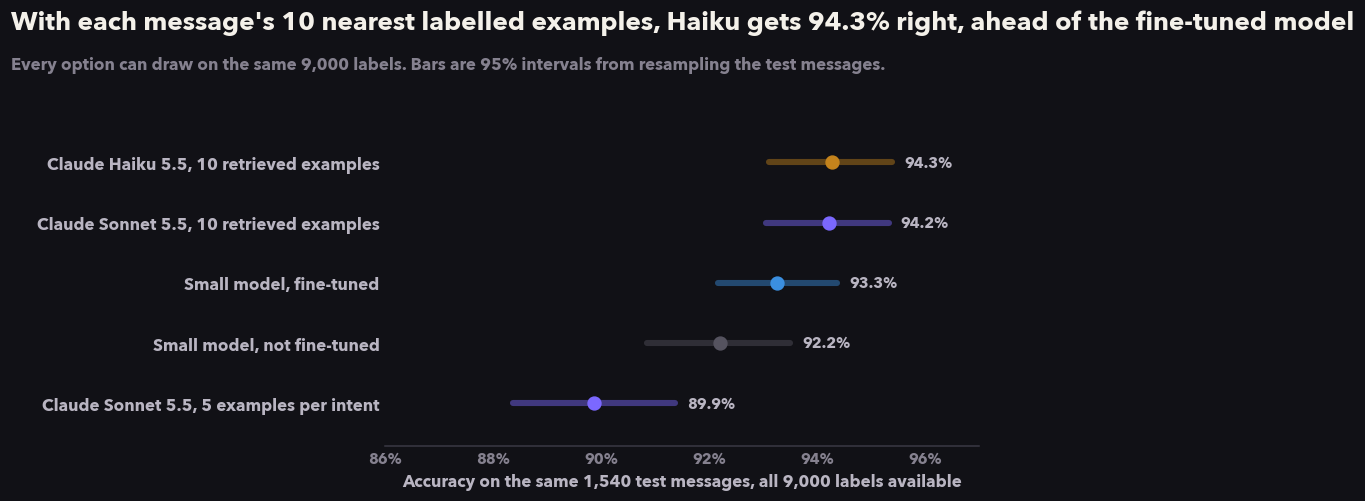

In [14]:
allin = pd.DataFrame({
    "Claude Haiku 5.5, 10 retrieved examples": correctness("haiku_retrieved10", "all").loc[rows],
    "Claude Sonnet 5.5, 10 retrieved examples": correctness("sonnet_retrieved10", "all").loc[rows],
    "Small model, fine-tuned": options["Small model, fine-tuned"][1].loc[rows],
    "Small model, not fine-tuned": options["Small model, not fine-tuned"][1].loc[rows],
    "Claude Sonnet 5.5, 5 examples per intent": correctness("sonnet", 5).loc[rows],
})
all_rows = pd.DataFrame([bootstrap_mean(allin[c]) for c in allin], columns=["value", "low", "high"])
all_rows["label"] = allin.columns
all_rows["colour"] = [style.APPROACH_COLORS[a] for a in ["haiku", "sonnet", "finetuned", "frozen", "sonnet"]]

fig, ax = plots.dot_intervals(all_rows, value_format="{:.1%}", zero_line=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Accuracy on the same 1,540 test messages, all 9,000 labels available")
ax.set_xlim(0.86, 0.97)
fig.subplots_adjust(top=0.76, left=0.36)
style.headline(fig, f"With each message's 10 nearest labelled examples, Haiku gets {all_rows['value'].iloc[0]:.1%} right, "
                    "ahead of the fine-tuned model",
               "Every option can draw on the same 9,000 labels. Bars are 95% intervals from resampling the test messages.")
style.save(fig, "all_labels_in_the_prompt")
pd.DataFrame({
    "Haiku, retrieved, minus fine-tuned": paired_difference(allin.iloc[:, 0], allin.iloc[:, 2]),
    "Sonnet, retrieved, minus fine-tuned": paired_difference(allin.iloc[:, 1], allin.iloc[:, 2]),
    "Haiku, retrieved, minus not fine-tuned": paired_difference(allin.iloc[:, 0], allin.iloc[:, 3]),
    "Haiku, retrieved, minus Sonnet, retrieved": paired_difference(allin.iloc[:, 0], allin.iloc[:, 1]),
}, index=["Difference", "95% low", "95% high"]).T.style.format(lambda v: f"{v * 100:+.1f} pts")

In [15]:
won = dis.index[dis["matches_label"] == "finetuned"]  # section 6: fine-tuned right, Sonnet (fixed examples) wrong
now = correctness("sonnet_retrieved10", "all").loc[won]
print(f"Of the {len(won)} messages where the fine-tuned model matched the label and Sonnet with fixed examples did not, "
      f"Sonnet with retrieved examples now matches the label on {int(now.sum())}.")

Of the 88 messages where the fine-tuned model matched the label and Sonnet with fixed examples did not, Sonnet with retrieved examples now matches the label on 71.


Given the labels in a form it can use, the prompted model catches up and passes the fine-tuned one, by about a point, even when scored strictly against the labels. Retrieved examples carry Banking77's labelling habits with them: the most similar training messages arrive with the labels their labellers chose, and most of the messages Sonnet used to lose to the fine-tuned model now go its way. So the fine-tuned model's lead in sections 1 and 2 came from seeing more labels, not from being fine-tuned. With retrieval, the cheap model is as good as the expensive one: Haiku and Sonnet are level.

This option is not free of the small model, though. Finding the similar examples needs an embedding model running for every request, and all the labels. Notebook 05 counts that.

## What this means

- **With few labels, prompt.** Given the same 385 examples, Haiku with the examples in its prompt beats both small models trained on them, and Sonnet is better still.
- **With many labels, how the prompt uses them matters more than fine-tuning.** With five fixed examples per intent, the prompts trail the fine-tuned model by 3 to 14 points. With each message's 10 nearest labelled examples, Haiku and Sonnet both get about 94% right, a point ahead of it.
- **The fine-tuned model's lead over fixed prompts is mostly agreement with the labellers.** Reading every disagreement with Sonnet, most of its extra right answers were cases where Sonnet's answer was just as defensible.
- **The model that was not fine-tuned is almost as good as the fine-tuned one.** A frozen embedding model with a linear classifier, trained in seconds, is about one point behind.
- **The hard messages are hard for everyone.** The options mostly fail on the same messages, and most of those are mislabelled or ambiguous. That caps every approach a few points below 100%.

**What the data can't tell us.** Each prompted run was made once, so the variation between reruns of the same prompt is not measured here. The verdicts in sections 5 and 6 are one reader's judgement. Only one retrieval setting was tried (10 examples, chosen by the frozen embeddings). And this is one short-message classification task; tasks with longer inputs, or where the hosted model's general knowledge matters, could favour prompting more.